# Plot for humans and all models combined

In [1]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('darkgrid')


## Create a complete dataframe

In [2]:
# Load the data
df = pd.read_csv('../data/model_matches.txt')
human = pd.read_csv('../../humans/data/human_results.csv', index_col='stimname')

df['difference'] = df['reflum'] - df['matchlum']
df = df.drop(columns={'matchlum', 'reflum'})

irn = df[df['model'] == 'irnet']

df = df.drop(columns={'run'})
odog = df.loc[df['model'] == 'odog', ['stimname', 'difference']]
retinex = df.loc[df['model'] == 'retinex99', ['stimname', 'difference']]
dbex = df.loc[df['model'] == 'dakinbex', ['stimname', 'difference']]

for frame in [odog, retinex, dbex]:
    frame.set_index('stimname', inplace=True)

diffs_per_illusion = {}
for index, row in irn.iterrows():
    ill_name = row['stimname']
    
    if ill_name not in diffs_per_illusion.keys():
        diffs_per_illusion[ill_name] = [row['difference']]
    else:
        diffs_per_illusion[ill_name].append(row['difference'])

mod_outputs = pd.DataFrame.from_dict(diffs_per_illusion).T
mod_outputs.index.name = 'stimname'
mod_outputs = pd.concat([mod_outputs, human], axis=1)

for frame, name in zip([odog, retinex, dbex], ['ODOG', 'Retinex', 'Dakin-Bex']): 
    mod_outputs[name] = frame['difference']

df = mod_outputs.copy()

cast = df[df.index.str.contains('X')]
control = df[df.index.str.endswith('c')]
paint = df[~df.index.str.endswith('c') & ~df.index.str.contains('X')]

df

,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,ODOG,Retinex,Dakin-Bex
stimname,,,,,,,,,,,,,,,,,,,,,
argyleX,12.364530,16.982765,17.167494,16.243847,12.918718,15.874388,16.243847,16.243847,17.352224,16.428577,...,12.148,11.274,12.804,11.444,8.466,5.736,8.296,1.018774,6.029388,1.571262
argyle,7.143111,8.816201,14.950862,6.585415,12.162380,8.258504,13.835469,13.835469,14.393166,13.277773,...,10.430,9.200,10.862,10.590,9.534,5.530,7.810,1.587084,5.627490,0.977060
argylec,11.604683,14.950862,17.739345,16.623952,14.393166,12.162380,16.066255,15.508559,14.950862,16.066255,...,3.456,7.580,-1.100,7.004,1.178,0.934,7.994,3.024534,12.442956,3.116401
argylelX,16.428577,16.613306,17.536953,16.428577,10.886695,15.135471,14.950741,16.243847,16.798035,15.504930,...,8.086,6.650,10.480,10.050,6.236,3.916,0.100,1.969297,6.549800,1.708808
argylel,1.566146,15.508559,13.277773,4.354629,11.046987,2.681539,13.277773,9.373897,7.700808,13.277773,...,8.110,4.818,6.262,10.984,2.498,3.014,4.364,1.314709,5.456954,0.552251
argylelc,13.277773,16.623952,17.181648,17.181648,12.162380,13.277773,15.508559,16.066255,10.489290,15.508559,...,2.772,3.964,-0.256,6.360,0.504,-0.188,-0.292,1.990364,10.604253,1.326139
checkassim,-0.841504,0.832311,-4.189135,4.737881,-9.210581,0.832311,3.064065,-4.189135,-6.420888,5.295819,...,0.200,-4.406,6.244,8.604,2.862,4.122,7.106,-1.262329,-0.998852,-1.412618
koffkac,-2.419508,16.550399,-0.187754,0.928122,12.644830,11.528953,13.760707,-0.187754,1.486061,10.971015,...,1.016,-0.116,10.610,8.902,-0.182,1.140,2.752,5.232278,4.278432,7.593047
koffkasX,13.377094,13.007635,17.256412,14.854929,14.854929,16.702223,15.593847,16.332765,18.364788,15.963306,...,11.656,10.508,14.102,13.860,13.024,7.620,5.842,4.859379,4.925616,9.046622


## Rename illusions and split dataframe

In [3]:
rename_dict = {
    'argyleX': 'Argyle Cast',
    'argyle': 'Argyle',
    'argylec': 'Argyle Control',
    'argylelX': 'Argyle Long Cast',
    'argylel': 'Argyle Long',
    'argylelc': 'Argyle Long Control',
    'checkassim': 'Checkboard',
    'koffkac': 'Koffka Control',
    'koffkasX': 'Koffka-Adelson Cast',
    'koffkas': 'Koffka-Adelson',
    'koffkatX': 'Koffka Broken Cast',
    'koffkat': 'Koffka Broken',
    'simconX': 'Simultaneous Contrast Cast',
    'simcon': 'Simultaneous Contrast',
    'simconaX': 'Simultaneous Contrast Articulated Cast',
    'simcona': 'Simultaneous Contrast Articulated',
    'snakeX': 'Snake Cast',
    'snake': 'Snake',
    'snakec': 'Snake Control',
    'white': 'White'
}

paint = paint.reindex(['argyle', 'argylel', 'koffkat', 'koffkas', 'simcon', 'simcona', 'snake', 'white', 'checkassim'])
cast = cast.reindex(['argyleX', 'argylelX', 'koffkatX', 'koffkasX', 'simconX', 'simconaX', 'snakeX'])
control = control.reindex(['argylec', 'argylelc', 'koffkac', 'snakec'])

for frame in [cast, paint, control]:
    frame.index = frame.index.map(rename_dict)



## Plot the complete results

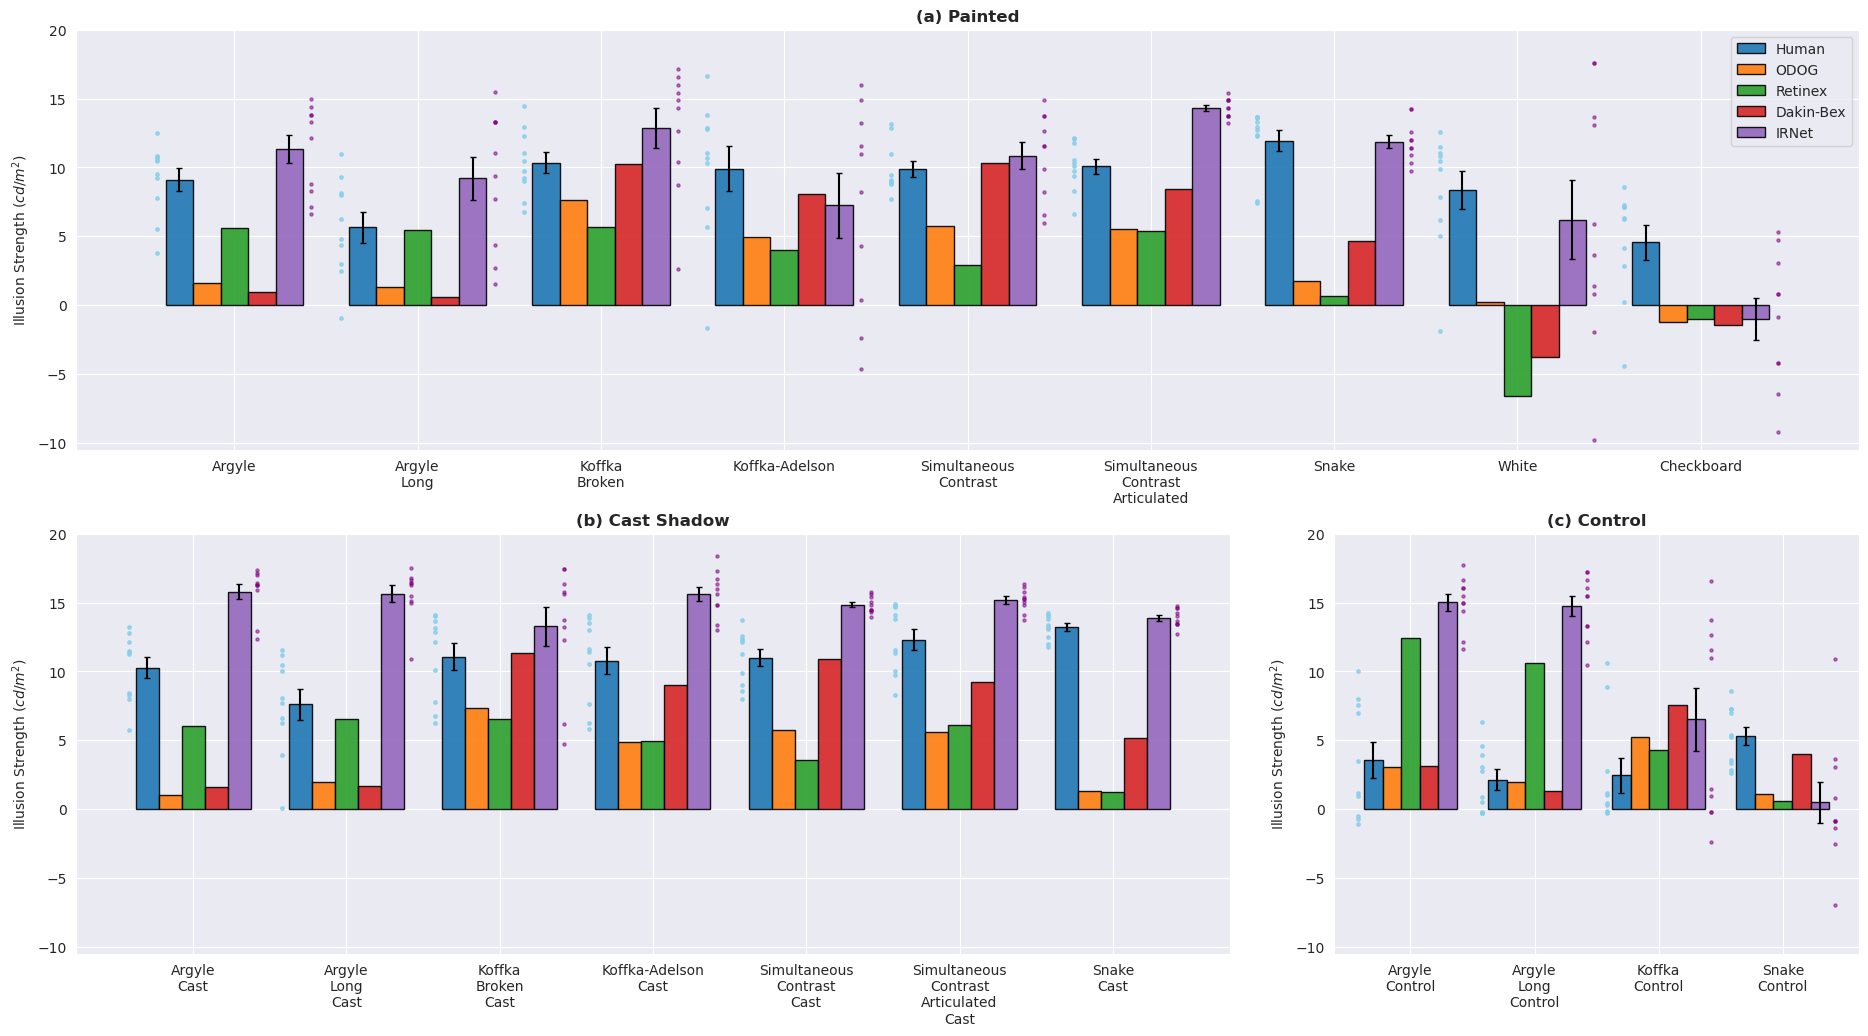

In [4]:
fig = plt.figure(figsize=(23, 12))

ax = []
gs = fig.add_gridspec(2, 3)
ax.append(fig.add_subplot(gs[0, :]))
ax.append(fig.add_subplot(gs[1, :2]))
ax.append(fig.add_subplot(gs[1, 2]))

titles = ['(a) Painted', '(b) Cast Shadow', '(c) Control']
for j, df in enumerate([paint, cast, control]):

    # Define clasical illusion columns
    classical_cols = ['ODOG', 'Retinex', 'Dakin-Bex']
    irn_cols = [i for i in range(10)]
    hum_cols = [str(i) for i in range(10, 20)]

    # IRNet and human mean and sem
    df['mean_runs'] = df[irn_cols].mean(axis=1)
    df['sem_runs'] = df[irn_cols].sem(axis=1)
    df['human_mean'] = df[hum_cols].mean(axis=1)
    df['human_sem'] = df[hum_cols].sem(axis=1)

    # Bar position parameters
    x = np.arange(len(df))
    bar_width, spacing, white_space = 0.15, 0.0, 0.0

    # Plot human results
    ax[j].bar(x + (-0.5 - len(classical_cols)/2) * (bar_width + spacing), df['human_mean'], width=bar_width, label='Human', edgecolor='black', alpha=0.9, yerr=df['human_sem'], capsize=2)

    # Plot classical models
    for i, model in enumerate(classical_cols, start=1):
        ax[j].bar(x + (-0.5 + i - len(classical_cols)/2) * (bar_width + spacing), df[model], width=bar_width, label=model, edgecolor='black', alpha=0.9)

    # Plot IRNet
    x_positions_mean_runs = x + (0.5 + white_space + len(classical_cols)/2) * (bar_width + spacing)
    ax[j].bar(x_positions_mean_runs, df['mean_runs'], width=bar_width, label='IRNet', edgecolor='black', alpha=0.9, yerr=df['sem_runs'], capsize=2)

    # Scatter plot for IRNet and humans
    for stim_idx in x:
        ax[j].scatter(np.full(10, stim_idx) + 0.42, df.iloc[stim_idx, :10], color='purple', alpha=0.5, s=5, edgecolor='purple')
        ax[j].scatter(np.full(10, stim_idx) - 0.42, df.iloc[stim_idx, 10:20], color='skyblue', alpha=0.8, s=6, edgecolor='skyblue')

    # Title, legend and illusion name formatting
    ax[j].set_title(titles[j], weight='bold')
    ax[j].set_xticks(x)
    ax[j].set_xticklabels([label.replace(" ", "\n") for label in df.index])
    ax[j].set_ylabel('Illusion Strength $(cd/m^2)$')
    ax[j].set_ylim(-10.5, 20)

plt.legend(bbox_to_anchor=(1.0, 2.2))
plt.show()


# Significance testing for classical models and IRNet

In [5]:
pnt, cst, ctr = pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

def drops(df, new):
    df = df.drop(columns={i if i < 10 else str(i) for i in range (20)})
    new = df.drop(columns={'human_sem', 'sem_runs'})
    new = new.rename(columns={'mean_runs': 'IRNet', 'human_mean': 'Human'})
    return new

pnt = drops(paint, pnt)
cst = drops(cast, cst)
ctr = drops(control, ctr)


## Classical model significance testing

In [6]:
ref_lum = 24.2

full_df = pd.concat([pnt, cst, ctr])
classical = full_df[['ODOG', 'Retinex', 'Dakin-Bex']]
bool_full = (classical > (ref_lum*0.06))

for mod in ['Retinex', 'ODOG', 'Dakin-Bex']:

    print(f"---{mod}---")

    for c, ill in zip(['Argyle Control', 'Argyle Long Control', 'Koffka Control', 'Koffka Control', 'Snake Control'], ['Argyle', 'Argyle Long', 'Koffka Broken', 'Koffka-Adelson', 'Snake']):

        print(f"{ill} Paint: {(classical.loc[ill][mod] - classical.loc[c][mod]) > 1.452}")
    
    print("")

    for c, ill in zip(['Argyle Control', 'Argyle Long Control', 'Koffka Control', 'Koffka Control', 'Snake Control'], ['Argyle Cast', 'Argyle Long Cast', 'Koffka Broken Cast', 'Koffka-Adelson Cast', 'Snake Cast']):

        print(f"{ill}: {(classical.loc[ill][mod] - classical.loc[c][mod]) > 1.452}")
    
    print("")

---Retinex---
Argyle Paint: False
Argyle Long Paint: False
Koffka Broken Paint: False
Koffka-Adelson Paint: False
Snake Paint: False

Argyle Cast: False
Argyle Long Cast: False
Koffka Broken Cast: True
Koffka-Adelson Cast: False
Snake Cast: False

---ODOG---
Argyle Paint: False
Argyle Long Paint: False
Koffka Broken Paint: True
Koffka-Adelson Paint: False
Snake Paint: False

Argyle Cast: False
Argyle Long Cast: False
Koffka Broken Cast: True
Koffka-Adelson Cast: False
Snake Cast: False

---Dakin-Bex---
Argyle Paint: False
Argyle Long Paint: False
Koffka Broken Paint: True
Koffka-Adelson Paint: False
Snake Paint: False

Argyle Cast: False
Argyle Long Cast: False
Koffka Broken Cast: True
Koffka-Adelson Cast: True
Snake Cast: False



## IRNet significance testing

In [8]:
df = pd.concat([paint, cast])
df = df.drop(columns={i if i < 10 else str(i) for i in range (20)})
df = df.drop(columns={'ODOG', 'Retinex', 'Dakin-Bex'})

df["t_irnet"] = ((df["mean_runs"] - 0) / df["sem_runs"]) > 1.812
df["t_human"] = ((df["human_mean"] - 0) / df["human_sem"]) > 1.812

comps_model = pd.DataFrame()
comps_human = pd.DataFrame()

for ctr, ill in zip(['Argyle Control', 'Argyle Long Control', 'Koffka Control', 'Koffka Control', 'Snake Control'], ['Argyle Cast', 'Argyle Long Cast', 'Koffka Broken Cast', 'Koffka-Adelson Cast', 'Snake Cast']):
    irnet_c, irnet_c_se = control.loc[ctr]['mean_runs'], control.loc[ctr]['sem_runs']
    human_c, human_c_se = control.loc[ctr]['human_mean'], control.loc[ctr]['human_sem']
    
    irnet, irnet_se = df.loc[ill]['mean_runs'], df.loc[ill]['sem_runs']
    human, human_se = df.loc[ill]['human_mean'], df.loc[ill]['human_sem']


### Signigicance for IRNet in a dataframe

In [9]:
df

,mean_runs,sem_runs,human_mean,human_sem,t_irnet,t_human
stimname,,,,,,
Argyle,11.325835,1.029181,9.1024,0.846858,True,True
Argyle Long,9.206588,1.562103,5.6396,1.137557,True,True
Koffka Broken,12.868005,1.424171,10.3330,0.764392,True,True
Koffka-Adelson,7.232827,2.343710,9.9148,1.627676,True,True
Simultaneous Contrast,10.859427,0.990417,9.8930,0.580315,True,True
Simultaneous Contrast Articulated,14.318645,0.220054,10.0902,0.552024,True,True
Snake,11.879493,0.469022,11.9422,0.759317,True,True
White,6.188521,2.871803,8.3380,1.369790,True,True
Checkboard,-1.008886,1.538243,4.5500,1.271035,False,True
